**Binary Image Classifier**

Classifies food images as either Pizza (Class 1) or Not Pizza (Class 0)

**Preparation**

In [1]:
import os, warnings
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.preprocessing import image

In [2]:
# removes sources of randomness for reproducability
def set_deterministic_environment(seed=31415):
    # environment variables
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
    # framework seeds
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed) # Keras-specific global wrapper

set_deterministic_environment(seed=31415)

In [3]:
# Matplotlib defaults
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large', titleweight='bold', 
       titlesize=18, titlepad=10)
plt.rc('image', cmap='magma')
warnings.filterwarnings('ignore')

**Loading Data**

In [4]:
data_dir = 'pizza_not_pizza'

# training data
ds_train_ = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2, #split raw data into 80% training, 20% validation 
    subset="training",
    seed=1, # same seed to prevent overlap
    image_size=(180, 180), 
    batch_size=32,
    shuffle=True,
    label_mode='binary'
)

# validation data
ds_valid_ = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=1, # same seed to prevent overlap
    image_size=(180, 180),
    batch_size=32,
    label_mode='binary'
)


Found 1997 files belonging to 2 classes.
Using 1598 files for training.
Found 1997 files belonging to 2 classes.
Using 399 files for validation.


2026-05-24 13:05:35.304973: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Max
2026-05-24 13:05:35.304996: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-05-24 13:05:35.305005: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-05-24 13:05:35.305026: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-24 13:05:35.305037: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [5]:
# data pipeline
def convert_to_float(image, label):
    image = tf.cast(image, tf.float32) / 255.0 # normalize (convert number 0-255 to 0.0 to 1.0)
    return image, label

AUTOTUNE = tf.data.experimental.AUTOTUNE
ds_train = ds_train_.map(convert_to_float).cache().prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
ds_valid = ds_valid_.map(convert_to_float).cache().prefetch(buffer_size=tf.data.experimental.AUTOTUNE)

**Creating Model**

In [6]:
from tensorflow import keras
from tensorflow.keras import layers, regularizers

# data augmentation 
# horizontal flip, rotation, zoom, contrast 
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2), 
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.1),
])

# building the actual model
model = keras.Sequential([
    layers.InputLayer([180,180,3]), # specifies inputs

    # augmentation
    data_augmentation,
    
    # block 1
    # scans for low level features 
    layers.Conv2D(filters=16, kernel_size=3, padding='same'),
    layers.Activation('relu'),
    layers.MaxPool2D(),

    # block 2
    # combines lines into shapes
    layers.Conv2D(filters=32, kernel_size=3, padding='same'),
    layers.Activation('relu'),
    layers.MaxPool2D(),

    # block 3
    # scans for more details/textures
    layers.Conv2D(filters=64, kernel_size=3, padding='same'),
    layers.Conv2D(filters=64, kernel_size=3, padding='same'),
    layers.Activation('relu'),
    layers.MaxPool2D(),
    
    # head
    layers.Flatten(), 
    # 128 node reasoning layer  
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)), #regularizer to prevent overfitting
    layers.Dropout(0.4), # prevents overfitting by deactivating 40$ of the neurons 
    layers.Dense(1, activation='sigmoid'), # forces an answer between 0.0 and 1.0
])


**Compiling and Training Model**

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), #lower learning rate to prevent overshooting optimal solution
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

# early stopping to avoid wasting time overfitting  
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7, # if the validation loss does not improve in 5 epochs in a row, then it stops training early
    restore_best_weights=True # saves the optimal weights
)

# made mistakes on class 0 (not pizza) twice as costly as those on class 1 (pizza)
# since the model kept guessing pizza on the test images
# prevent pizza heavy bias
class_weight = {0: 2.0, 1: 1.0}

# launch training loop for a max of 60 epochs
history = model.fit(
    ds_train, 
    validation_data = ds_valid,
    epochs=60, 
    class_weight=class_weight, # apply bias correcting weights
    callbacks=[early_stopping],
)

Epoch 1/60


2026-05-24 13:05:35.934821: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - binary_accuracy: 0.5150 - loss: 1.1875 - val_binary_accuracy: 0.4787 - val_loss: 0.9333
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - binary_accuracy: 0.5156 - loss: 1.0629 - val_binary_accuracy: 0.4812 - val_loss: 0.9027
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - binary_accuracy: 0.5582 - loss: 0.9934 - val_binary_accuracy: 0.5013 - val_loss: 0.8512
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - binary_accuracy: 0.5989 - loss: 0.9364 - val_binary_accuracy: 0.5363 - val_loss: 0.8038
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - binary_accuracy: 0.6295 - loss: 0.8898 - val_binary_accuracy: 0.6391 - val_loss: 0.7110
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - binary_accuracy: 0.6696 - loss: 0.8643 - val_binary_accuracy: 0.6391 - val_loss: 0.7228
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - binary_accuracy: 0.6740 - loss: 0.8419 - val_binary_accuracy: 0.6742 - val_loss: 0.6808
Epoch 8/60
50/50 ━━━━━━━

Plotting the Results

<Axes: >

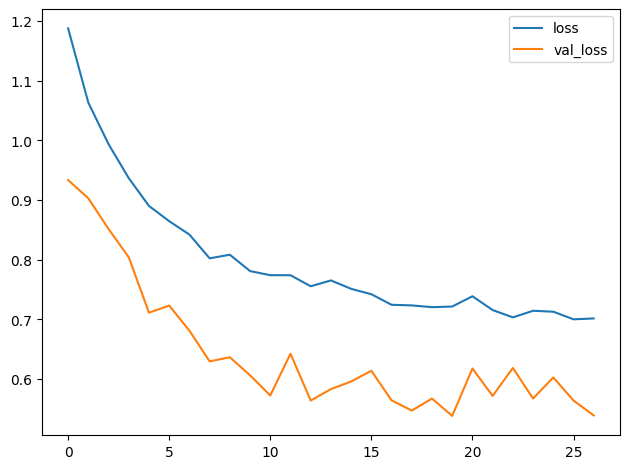

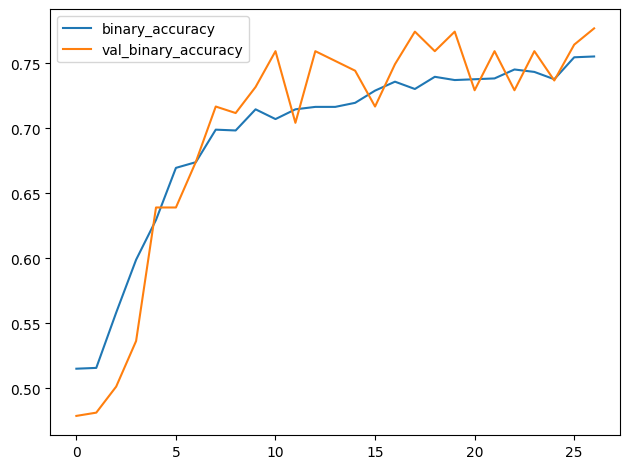

In [8]:
history_frame = pd.DataFrame(history.history)
history_frame.loc[:, ['loss', 'val_loss']].plot()
history_frame.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot()

**Testing**

In [9]:
from tensorflow.keras.utils import load_img, img_to_array
from IPython.display import Image, HTML

# looks for images and converts it into an array the model can handle
image_folder = './my_food_pics/' 
img_height, img_width = 180, 180
image_extensions = ('.png', '.jpg', '.jpeg', '.webp')
image_files = []

# loops through every single file inside the folder
for f in os.listdir(image_folder):
    # checks if the file ends with .png, .jpg, .jpeg, etc. (ignoring capital letters)
    if f.lower().endswith(image_extensions):
        image_files.append(f)


results_data = []
# loops through images and makes predictions
for file_name in image_files:
    file_path = os.path.join(image_folder, file_name)
    
    # loads and processes the image to how the model wants it
    img = load_img(file_path, target_size=(img_height, img_width))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) # model expects a batch
    img_array = img_array / 255.0 # normalize
    
    # run prediction to get raw probability score between 0.0 and 1.0
    prediction_score = model.predict(img_array, verbose=0)[0][0]

    # apply a optimized threshold based on testing results 
    threshold = 0.75
    # convert sigmoid output (0 to 1) into  binary classes
    # adjust the class names based on your actual dataset labels
    if prediction_score > threshold:
        predicted_class = "Pizza"
    else:
        predicted_class = "Not Pizza"
    
    # calculate the confidence score based on the prediction
    if prediction_score > threshold:
        confidence = prediction_score
    else:
        confidence = 1 - prediction_score
    
    # store data and a small HTML snippet to display the image inside the table
    results_data.append({
        "Photo In": f'<img src="{file_path}" width="100" style="border-radius: 5px;"/>',
        "Predicted Class": f"<b>{predicted_class}</b>",
        "Confidence Score": f"{confidence * 100:.2f}%"
    })

In [10]:
# create dataframe with the results
df = pd.DataFrame(results_data)

# create two more dataframes with the photos of the specific classes
pizza_df = df[df["Predicted Class"] == "<b>Pizza</b>"]
not_pizza_df = df[df["Predicted Class"] == "<b>Not Pizza</b>"]

# display the desired dataframe in the HTML table
desired_df = pizza_df
# set escape=False so the raw <img> tags render into physical pictures on screen
# index=False to hide unnecessary row numbers
HTML(desired_df[["Photo In", "Predicted Class", "Confidence Score"]].to_html(escape=False, index=False))

Photo In,Predicted Class,Confidence Score
,Pizza,85.81%
,Pizza,85.40%
,Pizza,85.89%
,Pizza,90.76%
,Pizza,99.00%
,Pizza,90.82%
,Pizza,82.85%
,Pizza,82.93%
,Pizza,88.17%
,Pizza,79.03%


In [11]:
# getting the total count of each class
print("Total Images: {}\n".format(len(df)))

print("Actual Pizza Images: 17")
print("Actual Not Pizza Images: {}\n".format(len(df)-17))

print("Total Pizza images: {}".format(len(pizza_df)))
print("Total Not Pizza images: {}".format(len(not_pizza_df)))

Total Images: 115

Actual Pizza Images: 17
Actual Not Pizza Images: 98

Total Pizza images: 13
Total Not Pizza images: 102
